In [1]:
%gui qt
from receiver import TJReceiver
from mantis.mini_interpreter import RawDataInterpreter
import numpy as np
import matplotlib.pyplot as plt

In [2]:
hit_dtype = np.dtype(
    [
        ("col", "<i2"),
        ("row", "<i2"),
        ("timestamp", "<i8"),
        ("rx_id", "<i2"),
    ]
)

received_data = []

In [3]:
def handle_data(data):
    # print("Received packet")
    received_data.append(data)


tj_receiver = TJReceiver(frontend="tcp://127.0.0.1:5501")
tj_receiver.worker.data.connect(handle_data)
tj_receiver.start()

In [ ]:
def make_hitmap(raw_data, rx_id=0):
    interpreter = RawDataInterpreter(rx_id=rx_id)
    # hit_buffer = np.zeros(4 * len(raw_data), dtype=hit_dtype)
    # hits = interpreter.interpret(raw_data, hit_buffer)
    occupancy = interpreter.hist_occ.sum(axis=2)
    return occupancy


def plot_hitmap(occupancy):
    plt.imshow(occupancy, cmap="hot", interpolation="nearest")
    plt.colorbar(label="Hits")
    plt.title("TJ-Monopix2 Hitmap")
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.show()

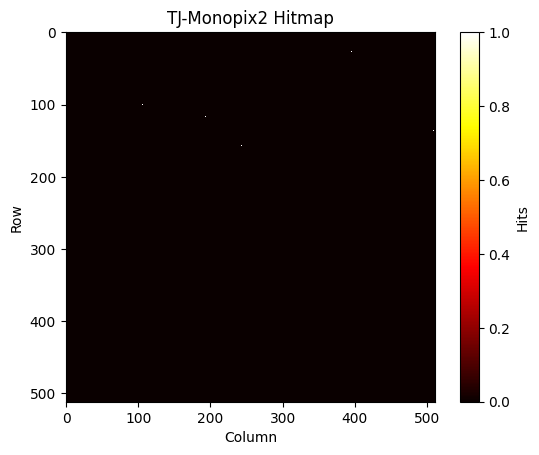

In [8]:
if len(received_data) > 0:
    packet = received_data[-1]

    raw_data = packet["raw"].astype(np.uint32)
    meta = packet["meta"]

    occ = make_hitmap(raw_data)
    plot_hitmap(occ)
else:
    print("No data received yet")